# **Decision Tree Model: Box Office Revenue Prediction**
### Ciaran O' Toole - C00297672
##### A portfolio produced as part of the Data Science & Machine Learning 1 Module in SE603, Bachelor of Science (Honours) Software Development at SETU

This notebook marks the first modelling stage of my portfolio, focusing on building, training, and evaluating a baseline **Decision Tree** model using my currated and verified dataset of 902 movies prepared in `Datasetcleansing.ipynb` and stored in `movies.csv`. The objective is to investigate whether a movie's production budget alone can accurately predict its worldwide box office revenue.


### **Step 1 - Load My Cleaned Data & Exploratory Overview (EDA)**

First, I load the verified dataset `movies.csv` containing the 902 movie records. Because Decision Trees capture non-linear relationships rather than assuming a constant linear slope. My goal here is to inspect the summary statistics and plot the raw distribution of **budget** against **revenue** without forcing a linear best-fit line.

             budget       revenue
count  9.020000e+02  9.020000e+02
mean   8.452772e+07  3.589842e+08
std    8.097168e+07  3.916373e+08
min    3.500000e+04  5.524000e+04
25%    1.900000e+07  7.750090e+07
50%    6.000000e+07  2.398537e+08
75%    1.385000e+08  5.047626e+08
max    6.588000e+08  2.942650e+09


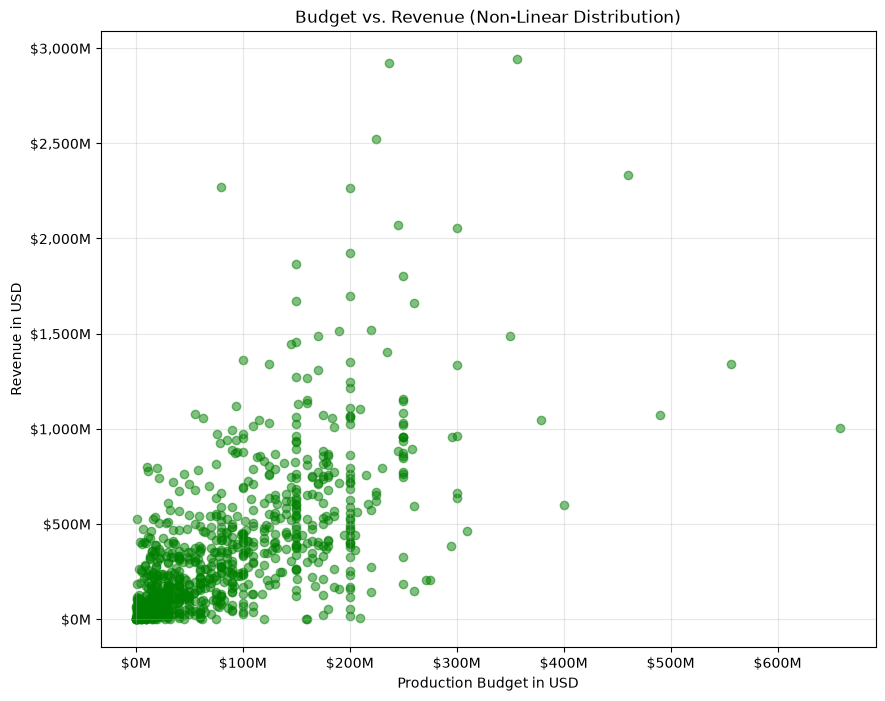

In [3]:
import pandas as pand
import numpy as np
from matplotlib.ticker import FuncFormatter
import matplotlib.pyplot as plot

# load my dataset
movies = pand.read_csv("movies.csv")

print(movies[["budget", "revenue"]].describe())

# displays the x and y nums as Millions rather than raw integers
numsformatter = FuncFormatter(lambda x, pos: f"${x / 1_000_000:,.0f}M")

plot.figure(figsize=(10, 8))
plot.scatter(movies["budget"], movies["revenue"], alpha=0.5, color="green")

plot.gca().xaxis.set_major_formatter(numsformatter)
plot.gca().yaxis.set_major_formatter(numsformatter)

plot.xlabel("Production Budget in USD")
plot.ylabel("Revenue in USD")
plot.title("Budget vs. Revenue (Non-Linear Distribution)")
plot.grid(True, alpha=0.3)
plot.show()

### **Step 2 - Data Preprocessing**

Before training the model, I prepare the dataset using the exact same split as my Linear Regression baseline, this keeps it fair across all models:

Only **budget** and **revenue** are needed. I make sure to stay consistent and split the data into an 80/20 training and testing split using `random_state=42` so all models are evaluated on the exact same 181 unseen test movies. Unlike Linear Regression, Decision Trees split data using threshold inequalities (e.g., `budget <= $50M`), which are invariant to monotonic scaling. Keeping **budget** in raw USD preserves identical splits while making the decision rules readable.

In [4]:
from sklearn.model_selection import train_test_split

x = movies[["budget"]]
y = movies["revenue"]

# create the training and test split in an 80/20 ratio like before
xtrainingset, xtestingset, ytrainingset, ytestingset = train_test_split( x, y, test_size=0.2, random_state=42)

print(f"Training set: {len(xtrainingset)}")
print(f"Testing set: {len(xtestingset)}")

Training set: 721
Testing set: 181


### **Step 3 - Model Training**

Now that the training and testing sets are prepared, I initialise scikit-learn's `DecisionTreeRegressor` and fit it on the training data. I set `max_depth=3` and `random_state=42` to prevent the tree from memorising individual training movies and overfitting the data. If i did not include a max depth the tree would just for every movie keep splitting which would not be ideal. We search from a depth of 1-9 to see which fits the best, doing this allows us to better fit and account for the model just fitting to noise, and we also do not want to underfit or overfit the model

In [9]:
from sklearn.tree import DecisionTreeRegressor
for depth in range(1, 10):
  test = DecisionTreeRegressor(max_depth=depth, random_state=42)
  test.fit(xtrainingset, ytrainingset)

  trainR2 = test.score(xtrainingset, ytrainingset)
  testR2 = test.score(xtestingset, ytestingset)

  print(f"| Train R2: {trainR2:.4f} | Test R2: {testR2:.4f} |")

| Train R2: 0.3163 | Test R2: 0.3703 |
| Train R2: 0.4316 | Test R2: 0.3719 |
| Train R2: 0.4630 | Test R2: 0.4193 |
| Train R2: 0.5155 | Test R2: 0.3244 |
| Train R2: 0.5587 | Test R2: 0.1653 |
| Train R2: 0.5885 | Test R2: 0.1533 |
| Train R2: 0.6062 | Test R2: 0.0970 |
| Train R2: 0.6190 | Test R2: 0.0447 |
| Train R2: 0.6233 | Test R2: 0.0219 |


As we can see from above, a `max_depth=3` of 3 is the sweet spot for the model we are training.

In [10]:

# sets up the model with a controlled max_depth to prevent overfitting
model = DecisionTreeRegressor(max_depth=3, random_state=42)
model.fit(xtrainingset, ytrainingset)

print(f"Tree Depth: {model.get_depth()}")
print(f"Number of Leaf Nodes: {model.get_n_leaves()}")

Tree Depth: 3
Number of Leaf Nodes: 8
